<a href="https://colab.research.google.com/github/analicepinho/C-lculo-Num-rico/blob/main/AtvPratica2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Atividade Prática 2
Cálculo Numérico
####**Analice Costa Pinho**
Prof Raquel J. Lobosco

###Dados:
*   distância de H = 0,01 m  
*   a placa localizada em y = 0 começa
a se mover com velocidade constante U = 1 m/s, enquanto a placa em y = H permanece fixa  
Quando 0 ≤ r ≤ 1/2, os coeficientes são não negativos e somam 1. A atualização funciona
como uma média ponderada.
Quando r > 1/2, o coeficiente central torna-se negativo, permitindo oscilações que podem
crescer e levar a overflow.  
**Caso A: ∆t = 0,001 s, com r = 0,4**  
**Caso B: ∆t = 0,002 s, com r = 0,8**
*  ∆y = 0,01/20 = 0,0005 m
*    ∆tmax = ∆y²/2v = (0,0005)²/2x10⁻⁴= 0,00125 s

Maior float32: 3.4028235e+38
Maior float64: 1.7976931348623157e+308
dt=0.001, float32: 200 passos sem overflow.
dt=0.002, float32: falha no passo 121, t=0.2420 s - overflow encountered in subtract
dt=0.001, float64: 200 passos sem overflow.
dt=0.002, float64: 200 passos sem overflow.


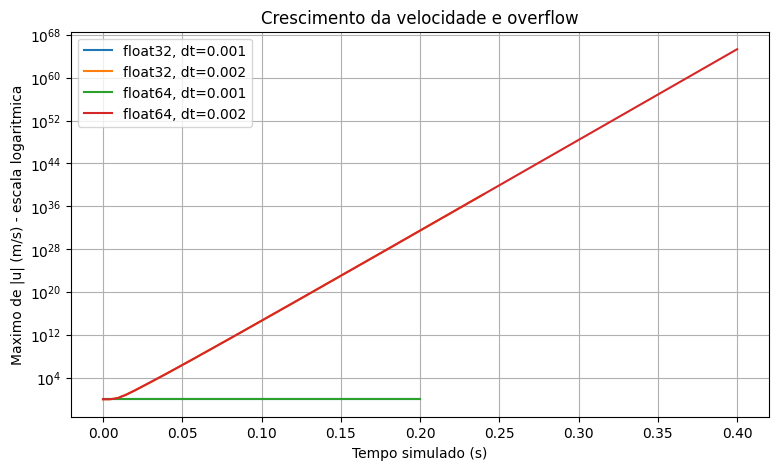

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


def simular(dt, tipo=np.float32, passos=200, pontos=21):
    """Simula difusao de velocidade e detecta falhas."""

    H = 0.01
    nu = 1e-4

    y = np.linspace(0, H, pontos)
    dy = H / (pontos - 1)

    # Coeficientes no tipo numerico escolhido.
    r = tipo(nu * dt / dy**2)
    dois = tipo(2)

    # Fluido parado e placa em y=0 em movimento.
    u = np.zeros(pontos, dtype=tipo)
    u[0] = tipo(1)

    tempos = [0.0]
    maximos = [float(np.max(np.abs(u)))]
    falha = None

    # Transforma avisos numericos em excecoes.
    with np.errstate(over="raise", invalid="raise"):
        for passo in range(1, passos + 1):
            try:
                novo = u.copy()

                # Atualiza o interior e preserva as paredes.
                novo[1:-1] = (
                    u[1:-1]
                    + r * (
                        u[2:] - dois * u[1:-1] + u[:-2]
                    )
                )

            except FloatingPointError as erro:
                falha = passo
                print(
                    f"dt={dt}, {tipo.__name__}: "
                    f"falha no passo {passo}, "
                    f"t={passo * dt:.4f} s - {erro}"
                )
                break

            u = novo
            tempos.append(passo * dt)
            maximos.append(float(np.max(np.abs(u))))

    if falha is None:
        print(
            f"dt={dt}, {tipo.__name__}: "
            f"{passos} passos sem overflow."
        )

    return {
        "y": y,
        "u": u,
        "tempos": tempos,
        "maximos": maximos,
        "r": float(r),
        "falha": falha,
    }


print("Maior float32:", np.finfo(np.float32).max)
print("Maior float64:", np.finfo(np.float64).max)

resultados = {}

for tipo in (np.float32, np.float64):
    for dt in (0.001, 0.002):
        nome = f"{tipo.__name__}, dt={dt}"
        resultados[nome] = simular(dt, tipo)

plt.figure(figsize=(9, 5))

for nome, resultado in resultados.items():
    plt.semilogy(
        resultado["tempos"],
        resultado["maximos"],
        label=nome
    )

plt.xlabel("Tempo simulado (s)")
plt.ylabel("Maximo de |u| (m/s) - escala logaritmica")
plt.title("Crescimento da velocidade e overflow")
plt.grid(True)
plt.legend()
plt.show()


**1. Verificação da estabilidade**  
*   Caso A: ∆t = 0,001 s, com **r = 0,4 < 0,5** ➩ Estável.    
*   Caso B: ∆t = 0,002 s, com **r = 0,8 > 0,5** ➩ Instável.

In [4]:
H_atv1 = 0.01
nu_atv1 = 1e-4
pontos_atv1 = 21

dy_atv1 = H_atv1 / (pontos_atv1 - 1)
dt_max_atv1 = (dy_atv1**2) / (2.0 * nu_atv1)

casos = [
    {"Caso": "Caso A", "dt (s)": 0.001},
    {"Caso": "Caso B", "dt (s)": 0.002}
]

dados_atv1 = []
for c in casos:
    r_val = nu_atv1 * c["dt (s)"] / (dy_atv1**2)
    dados_atv1.append({
        "Caso": c["Caso"],
        "dt (s)": c["dt (s)"],
        "dy (m)": dy_atv1,
        "dt_max (s)": dt_max_atv1,
        "r": r_val,
        "Classificação Prévia": "Estável" if r_val <= 0.5 else "Instável"
    })

df_atv1 = pd.DataFrame(dados_atv1)
display(df_atv1)

,Caso,dt (s),dy (m),dt_max (s),r,Classificação Prévia
0,Caso A,0.001,0.0005,0.00125,0.4,Estável
1,Caso B,0.002,0.0005,0.00125,0.8,Instável


**2. Detecção de overflow**

In [5]:
dados_atv2 = []

for nome, res in resultados.items():
    dados_atv2.append({
        "Teste": nome,
        "Valor de r": res["r"],
        "Houve Overflow?": "Sim" if res["falha"] is not None else "Não",
        "Iteração da Falha": res["falha"] if res["falha"] is not None else "Nenhuma"
    })

df_atv2 = pd.DataFrame(dados_atv2)
display(df_atv2)

,Teste,Valor de r,Houve Overflow?,Iteração da Falha
0,"float32, dt=0.001",0.4,Não,Nenhuma
1,"float32, dt=0.002",0.8,Sim,121
2,"float64, dt=0.001",0.4,Não,Nenhuma
3,"float64, dt=0.002",0.8,Não,Nenhuma


**3. Interpretação física**  
O crescimento observado no caso instável não representa o comportamento físico real porque, como a placa atua a U = 1m/s, a velocidade em qualquer ponto deveria variar no intervalo de 0 a 1 m/s. Valores altos vistos no gráfico decorrem de uma instabilidade numérica causada pela escolha de um passo de tempo acima do limite (r = 0,8 > 0,5), o que faz o algoritmo amplificar os erros a cada iteração até atingir o overflow.


**4. Capacidade de representação.**  
A mudança não elimina a instabilidade, porque ela é um problema matemático da fórmula quando escolhemos um passo r > 0,5, e não da precisão do computador. A diferença no número de passos até a falha acontece porque o float64 consegue guardar números muito maiores do que o float32.

**5. Refinamento da malha**  
Ao dobrar os intervalos: $\Delta y = \frac{0,01}{40} = 0,00025\text{ m}$.   
 O novo limite é: $\Delta t_{\max} = \frac{(0,00025)^2}{2 \times 10^{-4}} = 0,0003125\text{ s}$.  

In [7]:
pontos_5 = 41
dy_5 = 0.01 / (pontos_5 - 1)
dt_max_5 = (dy_5**2) / (2.0 * 1e-4)

print(f"Novo dy: {dy_5:.6f} m")
print(f"Novo dt_max: {dt_max_5:.6f} s\n")

res_5_instavel = simular(dt=0.001, tipo=np.float64, passos=2000, pontos=41)

res_5_estavel = simular(dt=0.00025, tipo=np.float64, passos=8000, pontos=41)

Novo dy: 0.000250 m
Novo dt_max: 0.000312 s

dt=0.001, float64: falha no passo 426, t=0.4260 s - overflow encountered in subtract
dt=0.00025, float64: 8000 passos sem overflow.


Com o refinamento para 41 pontos, o espaçamento caiu pela metade, o que reduziu drasticamente o limite máximo de estabilidade para 0,0003125 s. Ao manter $\Delta t = 0,001\text{ s}$, o parâmetro r subiu para 1,6 (> 0,5), tornando a simulação instável e gerando overflow no passo 426. Para corrigir a falha, escolheu-se $\Delta t = 0,00025\text{ s}$, resultando em r = 0,4 < 0,5, o que permitiu concluir todos os 8000 passos sem overflow.

**6. Verificação do perfil de velocidade.**

dt=0.001, float64: 5000 passos sem overflow.
Diferença máxima (E_inf): 3.441691e-15 m/s


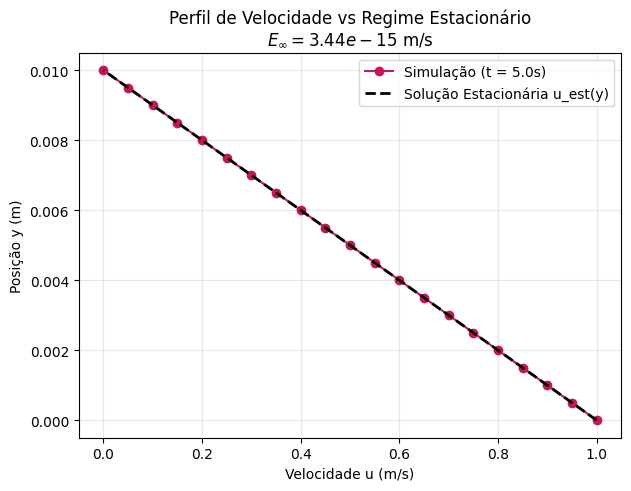

In [8]:
res_estavel = simular(dt=0.001, tipo=np.float64, passos=5000, pontos=21)

y_sim = res_estavel["y"]
u_sim = res_estavel["u"]

u_est = 1.0 * (1.0 - y_sim / 0.01)
E_inf = np.max(np.abs(u_sim - u_est))

print(f"Diferença máxima (E_inf): {E_inf:.6e} m/s")

plt.figure(figsize=(7, 5))
plt.plot(u_sim, y_sim, 'o-', color='#C2185B', label=f'Simulação (t = {res_estavel["tempos"][-1]:.1f}s)')
plt.plot(u_est, y_sim, '--', color='black', lw=2, label='Solução Estacionária u_est(y)')
plt.xlabel("Velocidade u (m/s)")
plt.ylabel("Posição y (m)")
plt.title(f"Perfil de Velocidade vs Regime Estacionário\n$E_\\infty = {E_inf:.2e}$ m/s")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**7. Conclusão.**

/tmp/ipykernel_450/134436726.py:72: RuntimeWarning: overflow encountered in scalar multiply
  ax_g1.text(i, v * 1.5, f"10^{int(np.log10(v))}", ha='center', fontsize=8.5, fontweight='bold')


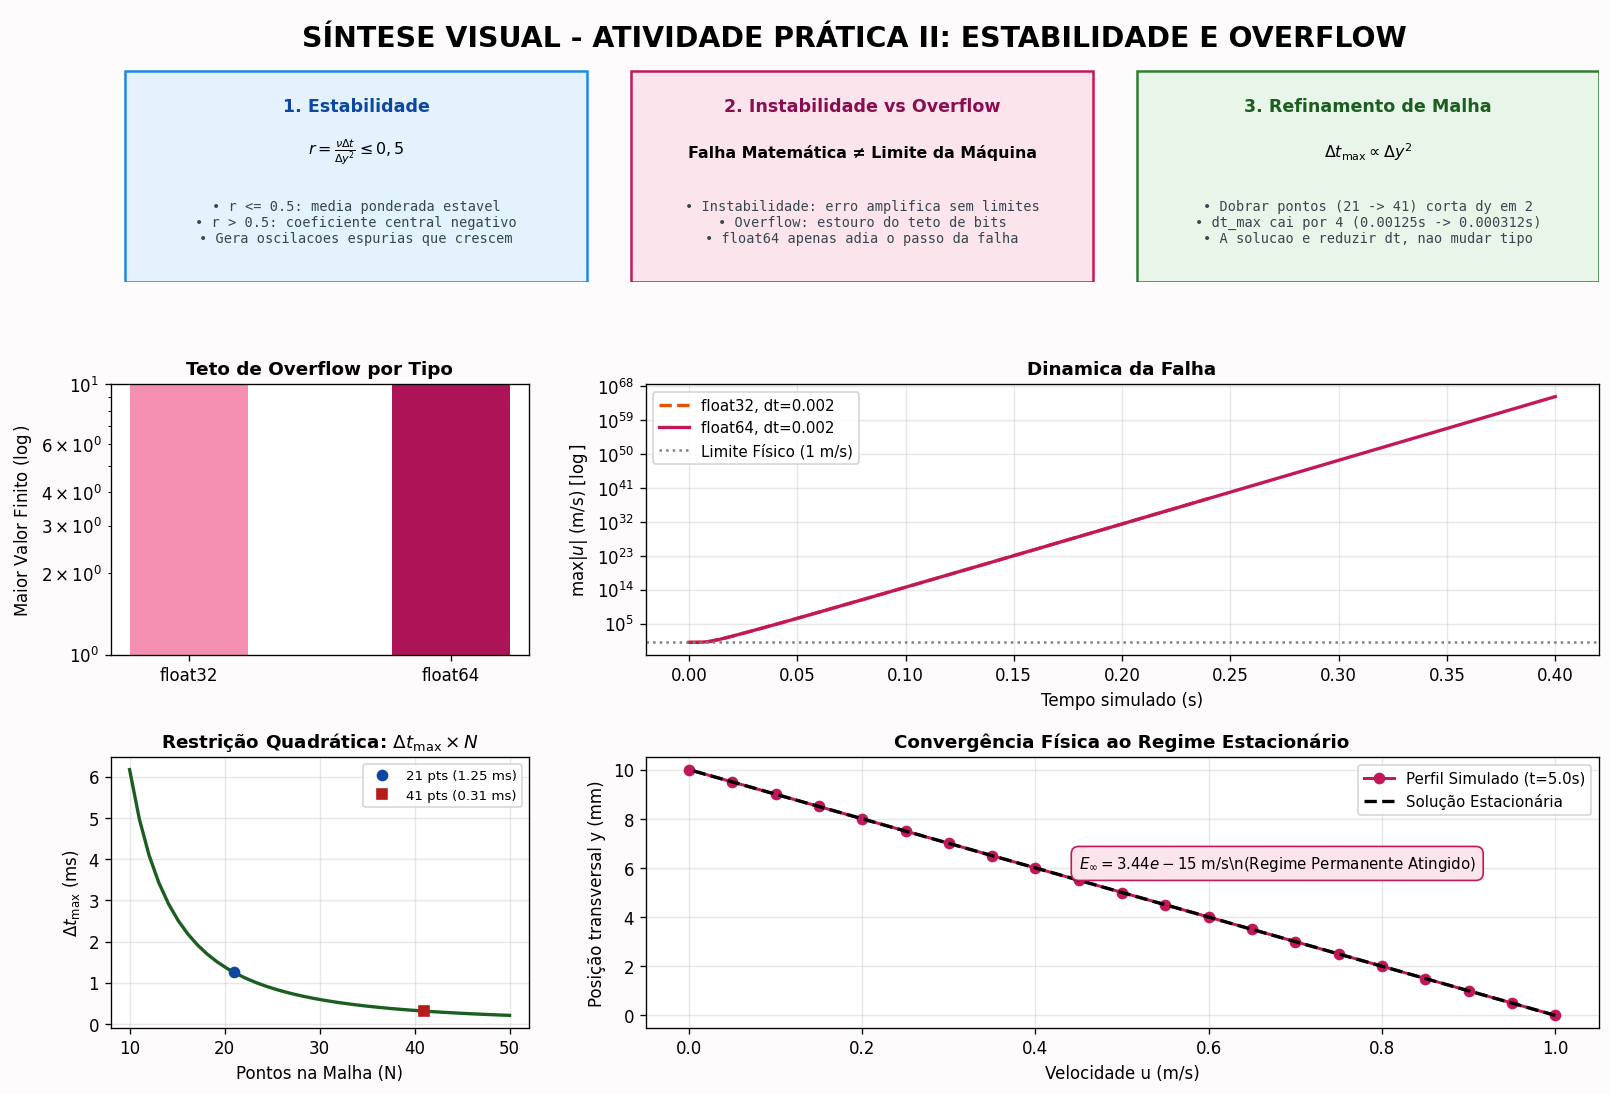

In [12]:
fig = plt.figure(figsize=(16, 11), dpi=120)
fig.patch.set_facecolor('#FDFBFC')

gs = fig.add_gridspec(3, 3, height_ratios=[1.0, 1.0, 1.0], hspace=0.38, wspace=0.28)

ax_top = fig.add_subplot(gs[0, :])
ax_top.axis('off')
ax_top.text(0.5, 0.90, 'SÍNTESE VISUAL - ATIVIDADE PRÁTICA II: ESTABILIDADE E OVERFLOW',
            ha='center', va='center', fontsize=17, fontweight='bold', color='black')

cartoes_conclusao = [
    {
        "titulo": "1. Estabilidade",
        "sub": r"$r = \frac{\nu \Delta t}{\Delta y^2} \leq 0,5$",
        "cor_borda": "#1E88E5",
        "cor_fundo": "#E3F2FD",
        "cor_txt": "#0D47A1",
        "linhas": [
            "• r <= 0.5: media ponderada estavel",
            "• r > 0.5: coeficiente central negativo",
            "• Gera oscilacoes espurias que crescem"
        ]
    },
    {
        "titulo": "2. Instabilidade vs Overflow",
        "sub": "Falha Matemática ≠ Limite da Máquina",
        "cor_borda": "#C2185B",
        "cor_fundo": "#FCE4EC",
        "cor_txt": "#880E4F",
        "linhas": [
            "• Instabilidade: erro amplifica sem limites",
            "• Overflow: estouro do teto de bits",
            "• float64 apenas adia o passo da falha"
        ]
    },
    {
        "titulo": "3. Refinamento de Malha",
        "sub": r"$\Delta t_{\max} \propto \Delta y^2$",
        "cor_borda": "#2E7D32",
        "cor_fundo": "#E8F5E9",
        "cor_txt": "#1B5E20",
        "linhas": [
            "• Dobrar pontos (21 -> 41) corta dy em 2",
            "• dt_max cai por 4 (0.00125s -> 0.000312s)",
            "• A solucao e reduzir dt, nao mudar tipo"
        ]
    }
]

for idx, c in enumerate(cartoes_conclusao):
    rect = plt.Rectangle((idx * 0.34 + 0.01, 0.0), 0.31, 0.78,
                         facecolor=c["cor_fundo"], edgecolor=c["cor_borda"], lw=1.5, transform=ax_top.transAxes)
    ax_top.add_patch(rect)

    x_c = idx * 0.34 + 0.165
    ax_top.text(x_c, 0.65, c["titulo"], ha='center', va='center', fontsize=10.5, fontweight='bold', color=c["cor_txt"], transform=ax_top.transAxes)
    ax_top.text(x_c, 0.48, c["sub"], ha='center', va='center', fontsize=9.5, fontweight='bold', color='black', transform=ax_top.transAxes)

    texto_bloco = "\n".join(c["linhas"])
    ax_top.text(x_c, 0.22, texto_bloco, ha='center', va='center', fontsize=8.2, family='monospace', color='#37474F', transform=ax_top.transAxes)

ax_g1 = fig.add_subplot(gs[1, 0])
tipos_mem = ['float32', 'float64']
limites_max = [np.finfo(np.float32).max, np.finfo(np.float64).max]
cores_bar = ['#F48FB1', '#AD1457']
ax_g1.bar(tipos_mem, limites_max, color=cores_bar, width=0.45)
ax_g1.set_yscale('log')
ax_g1.set_title('Teto de Overflow por Tipo', fontsize=11, fontweight='bold')
ax_g1.set_ylabel(r'Maior Valor Finito ($\log$)')
ax_g1.grid(axis='y', alpha=0.3)
for i, v in enumerate(limites_max):
    ax_g1.text(i, v * 1.5, f"10^{int(np.log10(v))}", ha='center', fontsize=8.5, fontweight='bold')

ax_g2 = fig.add_subplot(gs[1, 1:])
for nome in ['float32, dt=0.002', 'float64, dt=0.002']:
    if nome in resultados:
        cor = '#E65100' if 'float32' in nome else '#C2185B'
        ls = '--' if 'float32' in nome else '-'
        ax_g2.semilogy(resultados[nome]['tempos'], resultados[nome]['maximos'], label=nome, color=cor, linestyle=ls, lw=2)

ax_g2.axhline(1.0, color='gray', linestyle=':', label='Limite Físico (1 m/s)')
ax_g2.set_title('Dinamica da Falha', fontsize=11, fontweight='bold')
ax_g2.set_xlabel('Tempo simulado (s)')
ax_g2.set_ylabel(r'$\max |u|$ (m/s) [$\log$]')
ax_g2.grid(True, alpha=0.3)
ax_g2.legend(fontsize=9)

ax_g3 = fig.add_subplot(gs[2, 0])
pontos_teste = np.linspace(10, 50, 40)
dy_teste = 0.01 / (pontos_teste - 1)
dt_max_curva = (dy_teste**2) / (2.0 * 1e-4)

ax_g3.plot(pontos_teste, dt_max_curva * 1e3, color='#1B5E20', lw=2)
ax_g3.plot(21, ((0.01/20)**2 / (2e-4)) * 1e3, 'o', color='#0D47A1', label='21 pts (1.25 ms)')
ax_g3.plot(41, ((0.01/40)**2 / (2e-4)) * 1e3, 's', color='#B71C1C', label='41 pts (0.31 ms)')
ax_g3.set_title(r'Restrição Quadrática: $\Delta t_{\max} \times N$', fontsize=11, fontweight='bold')
ax_g3.set_xlabel('Pontos na Malha (N)')
ax_g3.set_ylabel(r'$\Delta t_{\max}$ (ms)')
ax_g3.grid(True, alpha=0.3)
ax_g3.legend(fontsize=8)

ax_g4 = fig.add_subplot(gs[2, 1:])
if 'res_estavel' in locals():
    ax_g4.plot(res_estavel['u'], res_estavel['y'] * 1e3, 'o-', color='#C2185B', lw=1.8, label='Perfil Simulado (t=5.0s)')
    ax_g4.plot(1.0 * (1.0 - res_estavel['y'] / 0.01), res_estavel['y'] * 1e3, '--', color='black', lw=2, label='Solução Estacionária')
    ax_g4.text(0.45, 6.0, rf"$E_\infty = {E_inf:.2e}$ m/s\n(Regime Permanente Atingido)",
               bbox=dict(boxstyle='round,pad=0.5', facecolor='#FCE4EC', edgecolor='#C2185B'), fontsize=9)
else:
    y_plot = np.linspace(0, 0.01, 21)
    ax_g4.plot(1.0 * (1.0 - y_plot / 0.01), y_plot * 1e3, '--', color='black', lw=2, label='Solução Estacionária')

ax_g4.set_title('Convergência Física ao Regime Estacionário', fontsize=11, fontweight='bold')
ax_g4.set_xlabel('Velocidade u (m/s)')
ax_g4.set_ylabel('Posição transversal y (mm)')
ax_g4.grid(True, alpha=0.3)
ax_g4.legend(fontsize=9)

plt.savefig('sintese_visual_conclusao.png', dpi=120, bbox_inches='tight')
plt.show()